# ArgoPAL tutorial

**ArgoPAL** turns the passive acoustic (PAL) measurements of BGC-Argo floats
into surface wind speed, starting from a float's WMO number and using only
data from the Argo GDAC.

This notebook walks through its functionalities on float **7902280**
(Ligurian Sea, 2026):

1. one-call processing
2. what the float measured
3. processing options
4. the pipeline step by step
5. figures to follow each step
6. wind speed from published models
7. calibration against reference buoys, with uncertainty
8. ship noise with AIS (optional)
9. export

Installation:

```
pip install git+https://github.com/louisedelaigue/ArgoPAL.git
pip install "argopal[ais] @ git+https://github.com/louisedelaigue/ArgoPAL.git"  # raw NMEA AIS
```

In [1]:
import warnings

import argopal

warnings.simplefilter("ignore")  # ArgoPAL warnings are discussed in the text
argopal.hello()


A  Wind from passive acoustics
r  on BGC-Argo floats
g
o  Version 0.1.0b1
P
A
L



## 1. One call

`process_float` downloads the float's files from the GDAC (acoustic spectra
from the *aux* folder; CTD, oxygen, pH and positions from the core files),
then runs every processing step.  Defaults: delayed-mode data only, 8 kHz
band, β per profile, despiking over ±1.5 h at the 95th percentile.

In [2]:
result = argopal.process_float(7902280, verbose=False)
list(result)

['park',
 'pal_raw',
 'park_samples',
 'profiles',
 'ts_profiles',
 'beta',
 'positions',
 'meta',
 'files']

`result["park"]` holds one row per acoustic measurement: band level, depth
correction β, depth-corrected spectral level, position, park T/S/O₂ and wind
speed from each published model.

In [3]:
park = result["park"]
cols = ["cycle", "datetime", "latitude", "longitude", "pressure",
        "f_8000Hz", "beta_8000Hz", "spl_8000Hz", "U_nystuen2015"]
park[cols].dropna().head()

,cycle,datetime,latitude,longitude,pressure,f_8000Hz,beta_8000Hz,spl_8000Hz,U_nystuen2015
0,1,2026-01-12 04:48:59.446877696,43.752416,9.103861,974.700012,47.625000,0.951016,48.576016,10.070965
1,1,2026-01-12 04:59:00.433076736,43.752426,9.103781,986.700012,47.666667,0.961430,48.628097,10.124104
2,1,2026-01-12 05:09:01.419275776,43.752437,9.103701,993.799988,47.750000,0.967585,48.717585,10.215942
3,1,2026-01-12 05:19:02.405474304,43.752448,9.103621,996.000000,47.727273,0.969493,48.696766,10.194515
4,1,2026-01-12 05:29:03.391673856,43.752458,9.103541,995.900024,47.708333,0.969406,48.677740,10.174967


In delayed mode, every value comes from delayed-mode Argo data only, with no
fallback.  For a young float, most profiles are not in delayed mode yet, so
the depth correction (and everything after it) is available only for the
first months:

In [4]:
print(f"{park['spl_8000Hz'].notna().mean():.0%} of measurements have a "
      f"depth-corrected level in {park.attrs['park']['mode']!r} mode")
cycles = result["ts_profiles"].attrs["cycles"]
print(f"profiles used for β: cycles {cycles[0]} to {cycles[-1]}")

63% of measurements have a depth-corrected level in 'delayed' mode
profiles used for β: cycles 1 to 37


## 2. What the float measured

The variables available in each file, with how many values are in delayed
(D), adjusted (A) and real-time (R) mode:

In [5]:
argopal.available_variables("argopal_data/7902280")

,file,variable,counted_per,n,n_D,n_A,n_R,n_adjusted_values
0,7902280_Rtraj.nc,TEMP,measurement,25443,0,0,25443,0
1,7902280_Rtraj.nc,PRES,measurement,124716,0,6148,118568,6148
2,7902280_Rtraj.nc,PSAL,measurement,25442,0,12911,12531,12911
3,7902280_Rtraj.nc,C1PHASE_DOXY,measurement,42769,0,0,42769,0
4,7902280_Rtraj.nc,C2PHASE_DOXY,measurement,42769,0,0,42769,0
5,7902280_Rtraj.nc,TEMP_DOXY,measurement,42769,0,0,42769,0
6,7902280_Rtraj.nc,DOXY,measurement,41869,0,41792,77,41792
7,7902280_Rtraj.nc,VRS_PH,measurement,20653,0,0,20653,0
8,7902280_Rtraj.nc,PH_IN_SITU_FREE,measurement,20653,0,0,20653,0
9,7902280_Rtraj.nc,PH_IN_SITU_TOTAL,measurement,20653,0,0,20653,0


The hydrophone and its configuration come from the `meta_aux` file.  This
float normalises band levels by bandwidth on board, so they are already
spectral levels:

In [6]:
meta = result["meta"]
print(meta["sensor_model"], meta["sensor_serial_no"])
print("band normalisation on board:", meta["band_normalization"])
print("spectra by band layout:", result["pal_raw"].attrs["band_layout_counts"])

HTI_96_MIN H31-01246
band normalisation on board: True
spectra by band layout: {'23': 306, '9': 71830, 'other': 0}


Almost all spectra are 9-band spectra (63, 125, 400 Hz, 1, 2, 5, 8, 12.5,
20 kHz), stored in the 23-band array with the other bands empty:

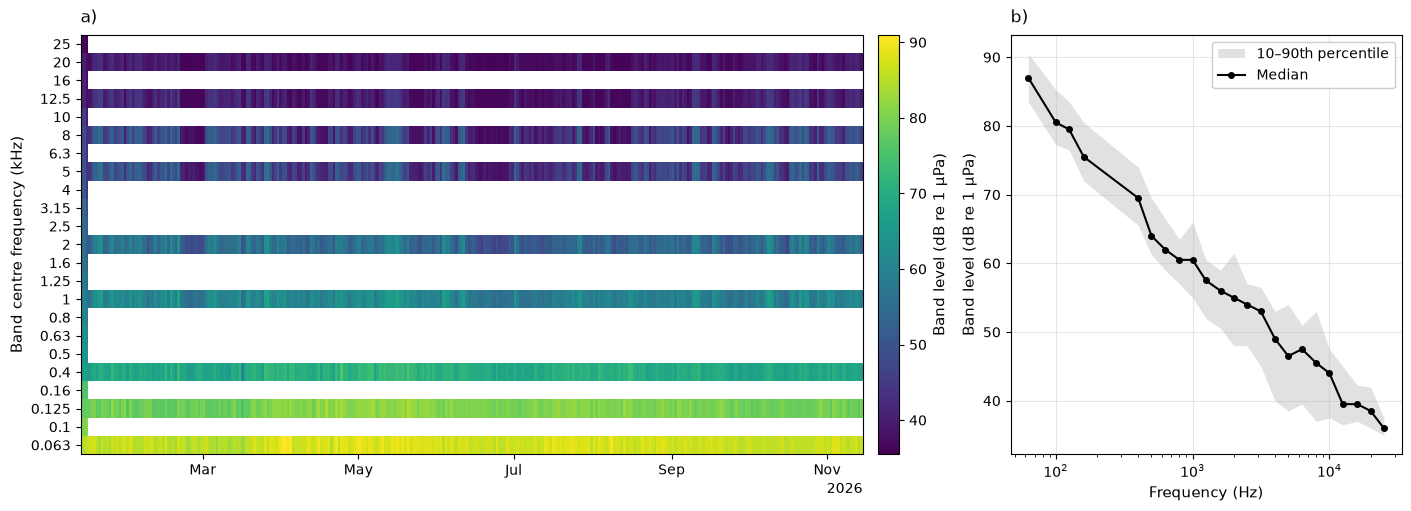

In [7]:
fig, axes = argopal.plot_pal_spectra(result["pal_raw"])

## 3. Options

- `mode`: `"delayed"` (default), `"adjusted"` or `"raw"`; one source each,
  no fallback.
- `bands`: frequency bands to process; default 8 kHz.  Bands without data
  are dropped with a warning (here 3.15 kHz, absent from 9-band spectra).
- `despike_window`, `despike_percentile`; `beta_method="mean"` for one β
  from the deployment-mean profile.

In [8]:
with warnings.catch_warnings(record=True) as caught:
    warnings.simplefilter("always")
    raw = argopal.process_float(7902280, mode="raw", bands=(3150, 8000), verbose=False)
print([str(w.message)[:110] for w in caught if "band" in str(w.message)])
print("bands processed:", raw["park"].attrs["bands_hz"])
print(f"depth-corrected in raw mode: {raw['park']['spl_8000Hz'].notna().mean():.0%}")

['WMO 7902280: the 3150 Hz band is not used: it has values in only 0.4% of spectra. Bands with data: 63, 125, 40']
bands processed: [8000]
depth-corrected in raw mode: 100%


## 4. Step by step

Each step of `process_float` is a function of its own; tables can be
inspected, changed or exported between steps.

In [9]:
files = argopal.download_aux(7902280, verbose=False) | argopal.download_core(7902280, verbose=False)

meta = argopal.read_pal_meta(files["7902280_meta_aux.nc"])
pal = argopal.read_pal(files["7902280_Rtraj_aux.nc"], meta=meta)           # spectra
pal = argopal.select_bands(pal, bands=8000)                                # 8 kHz
pal = argopal.clean_pal(pal)                                               # park drift, QC, despike

park_samples = argopal.read_park(files["7902280_Rtraj.nc"], mode="raw")    # park CTD/BGC
pal = argopal.attach_park(pal, park_samples)                               # linear in time
pal = argopal.attach_positions(pal, argopal.read_positions(files["7902280_Rtraj.nc"]))

profiles = argopal.read_profiles(files["7902280_Sprof.nc"], mode="raw")
ts = argopal.gridded_profiles(profiles, max_pressure=pal["pressure"].max() + 10)
beta = argopal.compute_profile_betas(ts, pal.attrs["bands_hz"])           # β per profile
pal = argopal.depth_correct(pal, beta)                                     # β in time and depth
pal = argopal.spectral_level(pal)                                          # dB re 1 µPa² Hz⁻¹
pal = argopal.wind_literature(pal)                                         # published models

pal[["datetime", "pressure", "f_8000Hz", "beta_8000Hz", "spl_8000Hz",
     "U_vagle1990", "U_nystuen2015", "U_pensieri2015"]].dropna().head()

,datetime,pressure,f_8000Hz,beta_8000Hz,spl_8000Hz,U_vagle1990,U_nystuen2015,U_pensieri2015
0,2026-01-12 04:48:59.446877696,974.700012,47.625000,0.951016,48.576016,6.672732,10.070965,8.456901
1,2026-01-12 04:59:00.433076736,986.700012,47.666667,0.961430,48.628097,6.702976,10.124104,8.511465
2,2026-01-12 05:09:01.419275776,993.799988,47.750000,0.967585,48.717585,6.755340,10.215942,8.605786
3,2026-01-12 05:19:02.405474304,996.000000,47.727273,0.969493,48.696766,6.743112,10.194515,8.583779
4,2026-01-12 05:29:03.391673856,995.900024,47.708333,0.969406,48.677740,6.731961,10.174967,8.563700


## 5. Figures

One figure per step, in the style of Delaigue et al. (2026).
`argopal.plot_all(result, save_dir="figures")` saves all of them at 300 dpi;
here a few, on the raw-mode run.

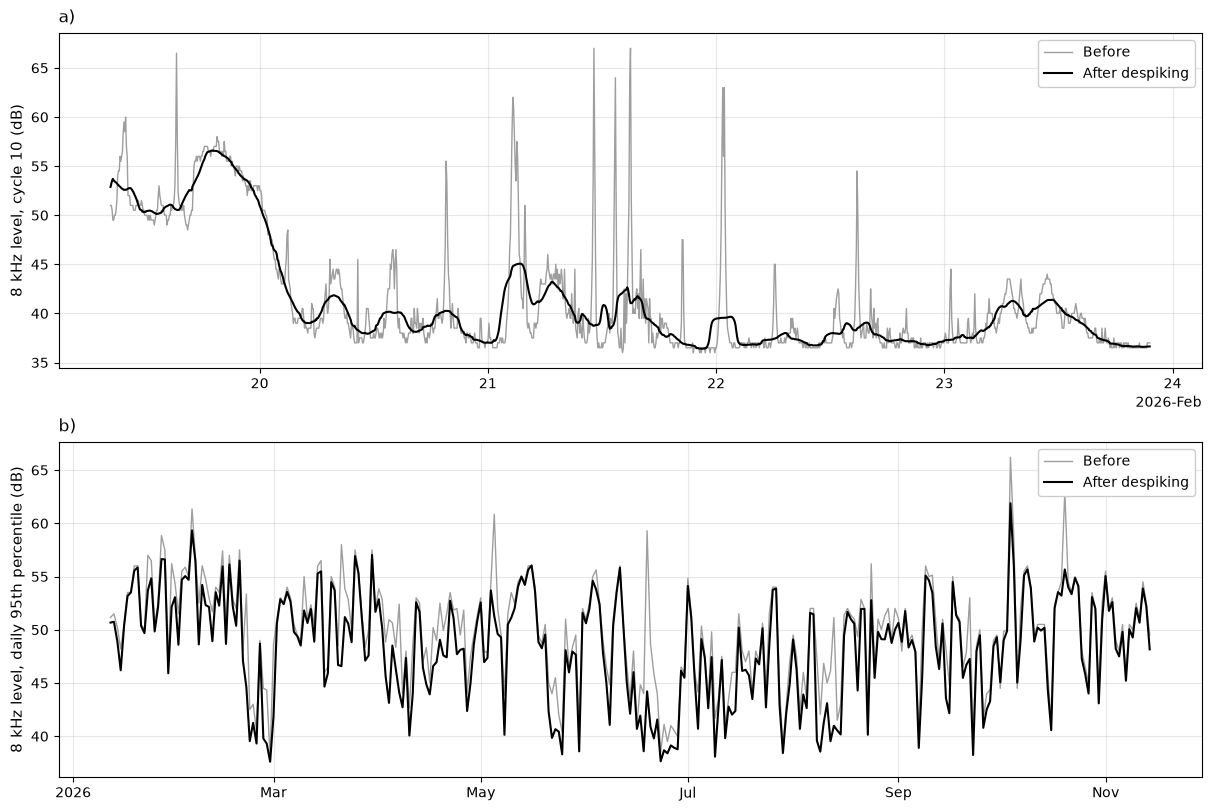

In [10]:
fig, axes = argopal.plot_despike(raw["pal_raw"], raw["park"], cycle=10)

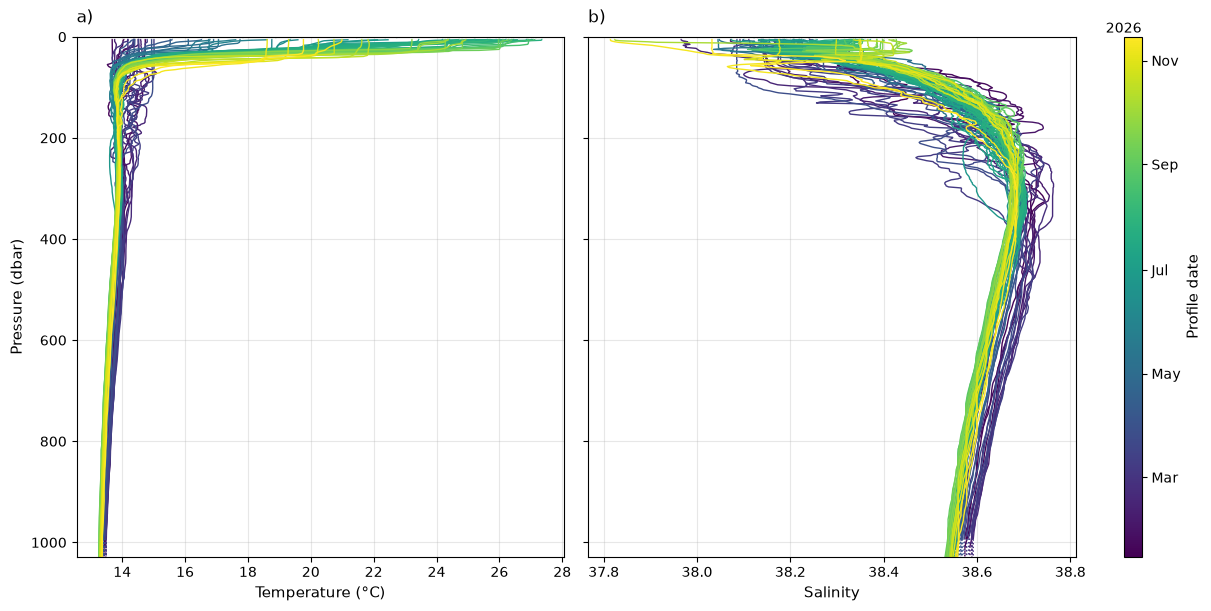

In [11]:
fig, axes = argopal.plot_profiles(raw["ts_profiles"])

β follows the season: the summer thermocline changes the sound-speed
profile and so the propagation of surface noise down to the hydrophone.

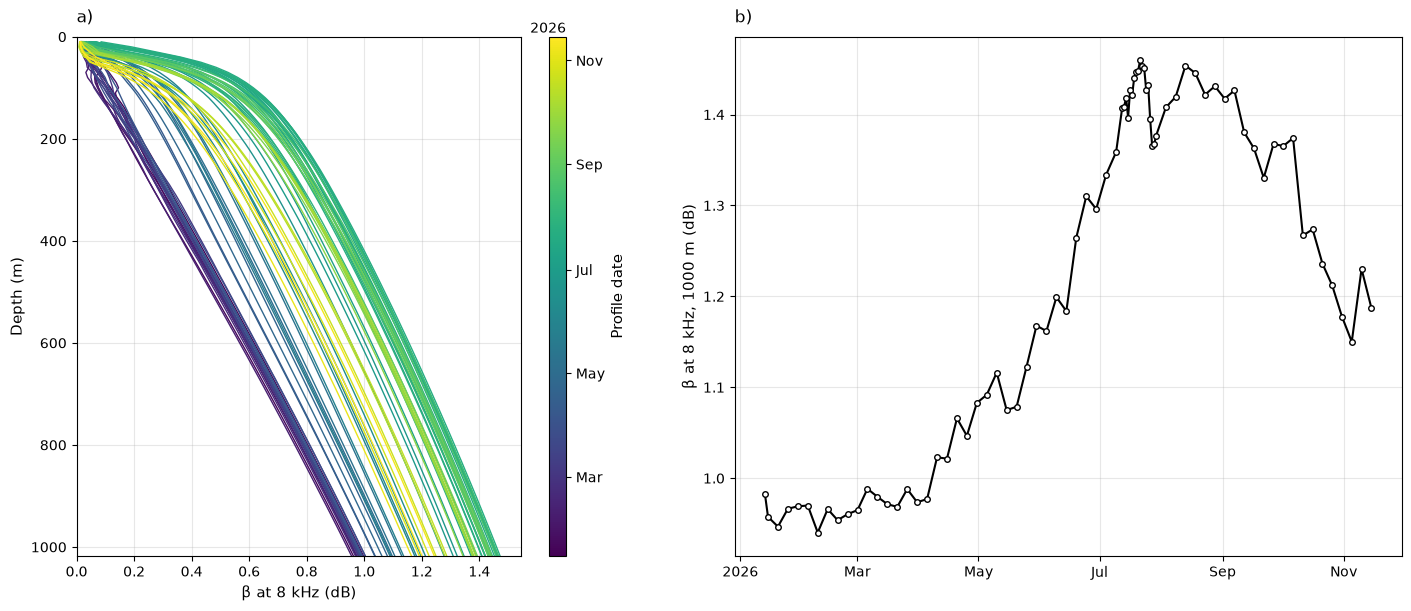

In [12]:
fig, axes = argopal.plot_beta(raw["beta"])

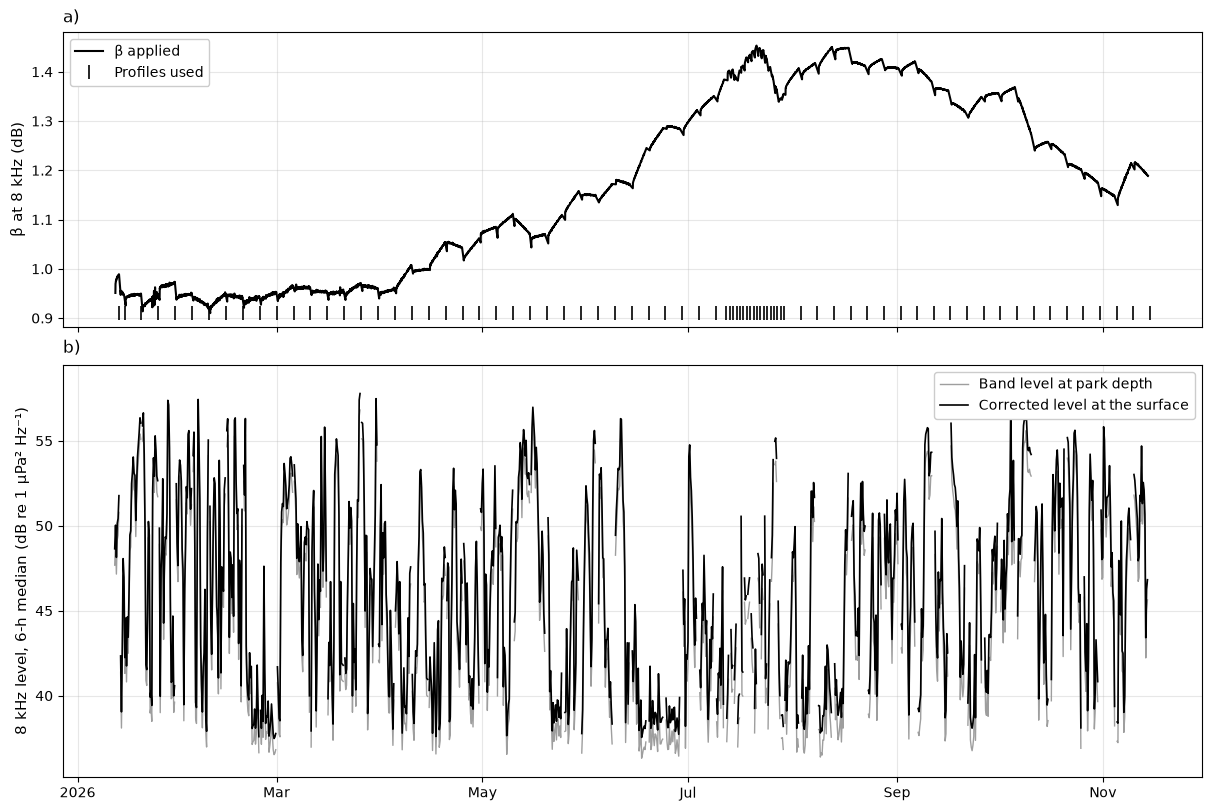

In [13]:
fig, axes = argopal.plot_depth_correction(raw["park"], beta=raw["beta"])

## 6. Wind speed from published models

Vagle et al. (1990), Nystuen et al. (2015) and Pensieri et al. (2015), all at
8 kHz, with their published coefficients (`U_<model>` columns).  Each is also
a function: e.g. `argopal.wind_nystuen2015(spl)`.

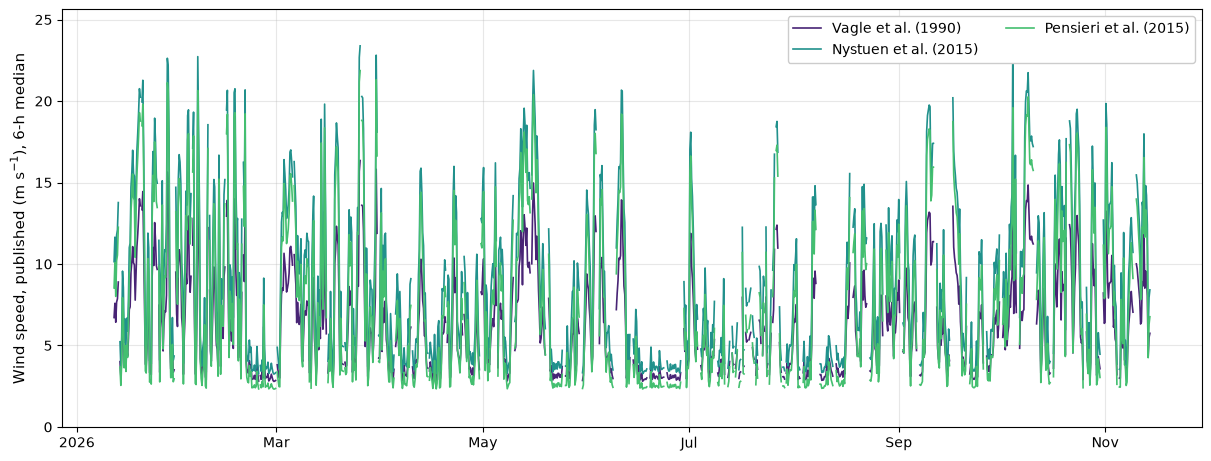

In [14]:
fig, axes = argopal.plot_wind(raw["park"])

## 7. Calibration against reference buoys

Published coefficients are not tuned to floats.  With a reference wind, the
models are refitted (nonlinear least squares, measurements within 40 km of
a reference), and each refitted wind gets an uncertainty.

ArgoPAL does not download reference winds: one table holds them all, here
three Météo-France buoys (DYFAMED, LION, PACA), January–June 2026.  Columns
`reference_name`, `datetime`, `latitude`, `longitude`, `wind_speed`, and
optionally `wind_speed_sigma`, the error of each value.

In [15]:
import pandas as pd

buoys = pd.read_csv("data/reference_winds_2026.csv")
buoys.groupby("reference_name")[["latitude", "longitude"]].mean().round(2)

,latitude,longitude
reference_name,,
DYFAMED,43.36,7.84
LION,42.10,4.68
PACA,42.45,6.84


Each measurement is matched to the closest buoy with a value within 1 h.

The float measures every 5 min and the buoys report hourly.  So for each
buoy value, the measurements from **30 min before to 30 min after** its
time are averaged first (`reference_window="1h"`, the default; any width
can be given, e.g. `"30min"` or `"3h"`).  The models are fitted and
assessed on these hourly points, then applied to every measurement.

`fit_max_distance_km` sets the radius used for fitting, skill and
uncertainty (40 km by default).  The buoys give no error per value, so one
error for all of them is passed as `reference_sigma`.

In [16]:
cal = argopal.process_float(
    7902280,
    mode="raw",
    reference={"buoys": "data/reference_winds_2026.csv"},
    fit_max_distance_km=40,
    reference_sigma=0.5,   # the buoys' wind error (m s⁻¹)
    verbose=False,
)
cal["park"].attrs["references"]["buoys"]["references"]

{'DYFAMED': 14977, 'LION': 48, 'PACA': 27155}

The float passed within 40 km of DYFAMED in February 2026 (cycles 9–12)
and of PACA in April 2026 (cycles 17–22); LION is always more than 100 km
away.  The refit pools the measurements near both buoys.

In [17]:
p = cal["park"]
p.groupby("buoys_reference_name")["buoys_distance_km"].describe()[
    ["count", "min", "50%", "max"]
].round(1)

,count,min,50%,max
buoys_reference_name,,,,
DYFAMED,14977.0,23.3,67.1,110.6
LION,48.0,113.7,123.9,133.2
PACA,27155.0,14.0,57.8,135.9


In [18]:
cal["wind_fits"][["model", "n", "rmse_published", "rmse_fitted",
                  "r2_published", "r2_fitted", "bias_published", "bias_fitted"]].round(2)

,model,n,rmse_published,rmse_fitted,r2_published,r2_fitted,bias_published,bias_fitted
0,vagle1990,930,2.07,1.99,0.68,0.71,-0.11,0.0
1,nystuen2015,930,3.02,1.99,0.33,0.71,1.95,-0.0
2,pensieri2015,930,2.32,2.01,0.61,0.70,0.53,-0.0


Skill of every wind estimate against the buoys within 40 km, all together
and per buoy:

In [19]:
cal["wind_skill"].round(2)

,wind,reference,reference_name,n,bias,rmse,r2,pearson_r2,slope,intercept
0,U_vagle1990,buoys,all,930,-0.11,2.07,0.68,0.71,0.58,2.09
1,U_vagle1990_fit,buoys,all,930,0.00,1.99,0.71,0.71,0.71,1.54
2,U_nystuen2015,buoys,all,930,1.95,3.02,0.33,0.70,0.96,2.17
3,U_nystuen2015_fit,buoys,all,930,-0.00,1.99,0.71,0.71,0.71,1.52
4,U_pensieri2015,buoys,all,930,0.53,2.32,0.61,0.70,0.93,0.89
5,U_pensieri2015_fit,buoys,all,930,-0.00,2.01,0.70,0.70,0.70,1.56
6,U_vagle1990,buoys,DYFAMED,334,-0.61,2.56,0.70,0.78,0.55,1.84
7,U_vagle1990_fit,buoys,DYFAMED,334,-0.53,2.32,0.75,0.78,0.67,1.25
8,U_nystuen2015,buoys,DYFAMED,334,1.21,2.56,0.70,0.78,0.90,1.74
9,U_nystuen2015_fit,buoys,DYFAMED,334,-0.58,2.31,0.75,0.78,0.68,1.15


Uncertainty, per measurement and per refitted model:

- `_sigma_cv`: empirical error, cross-validated by leaving one cycle out,
  binned by wind speed;
- `_sigma_coef`: coefficient uncertainty, bootstrap over cycles;
- `_sigma_ref`: the buoys' own error (`reference_sigma`, or the table's
  `wind_speed_sigma`);
- `_sigma`: combined, √(σ_cv² − σ_ref² + σ_coef²).

The empirical error by wind-speed bin:

In [20]:
cal["wind_uncertainty"].round(2)

,model,wind,sigma_cv,n,lo,hi
0,vagle1990,3.04,1.52,450,2.0,4.0
1,vagle1990,4.92,2.43,200,4.0,6.0
2,vagle1990,6.82,1.91,127,6.0,8.0
3,vagle1990,8.87,2.69,71,8.0,10.0
4,vagle1990,10.94,3.59,42,10.0,12.0
5,vagle1990,14.74,2.54,40,12.0,22.0
6,nystuen2015,2.92,1.52,423,0.0,4.0
7,nystuen2015,4.93,2.33,229,4.0,6.0
8,nystuen2015,6.84,1.97,133,6.0,8.0
9,nystuen2015,8.90,2.80,65,8.0,10.0


Ten cycles pass within 40 km of a buoy, the minimum ArgoPAL asks for the
bootstrap; with fewer, it warns that the coefficient term is unreliable.
The refit should still not be trusted far outside the winds seen near the
buoys.

In [21]:
cols = [c for c in cal["park"] if c.startswith("U_nystuen2015_fit_sigma")]
cal["park"][cols].quantile([0.5, 0.9]).round(2)

,U_nystuen2015_fit_sigma_cv,U_nystuen2015_fit_sigma_coef,U_nystuen2015_fit_sigma_ref,U_nystuen2015_fit_sigma
0.5,2.14,0.39,0.5,2.12
0.9,3.11,0.81,0.5,3.18


Refitted wind against the buoys, coloured by distance (as in Fig. 5 of
Delaigue et al. 2026).  By default the figure shows every measurement within
80 km, so its statistics include measurements further away than those used
for fitting:

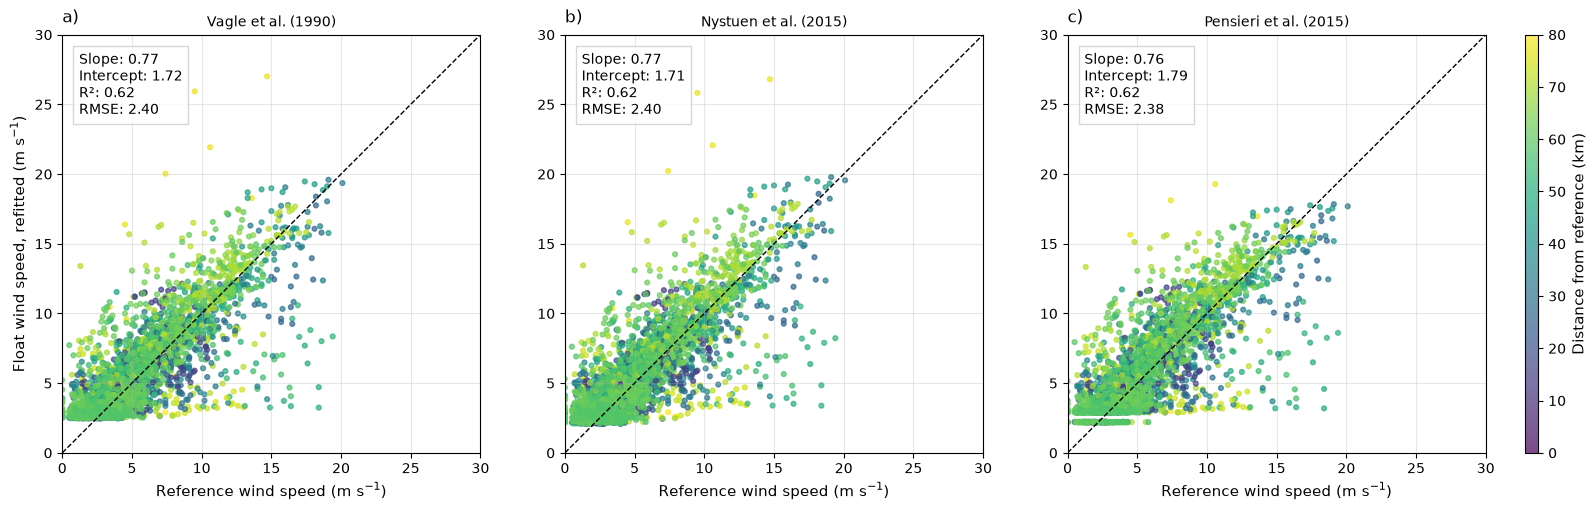

In [22]:
fig, axes = argopal.plot_wind_fit(cal["park"])

Restricted to the 40 km used for fitting, the statistics match `wind_fits`:

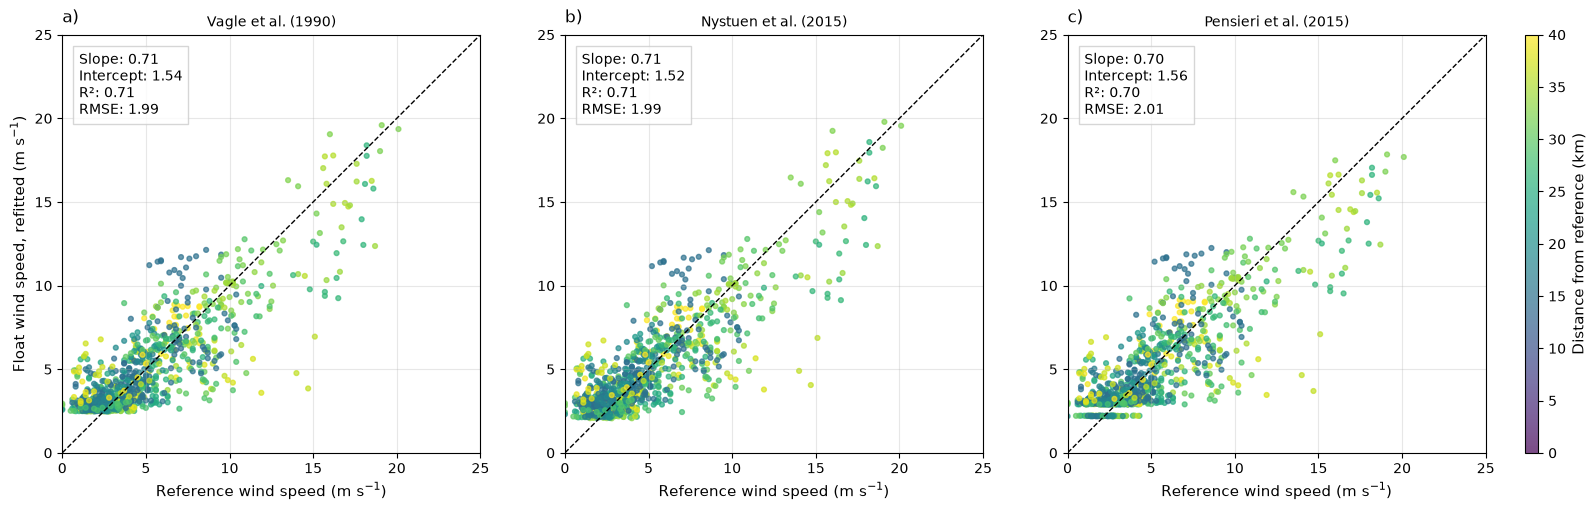

In [23]:
fig, axes = argopal.plot_wind_fit(cal["park"], max_distance_km=40)

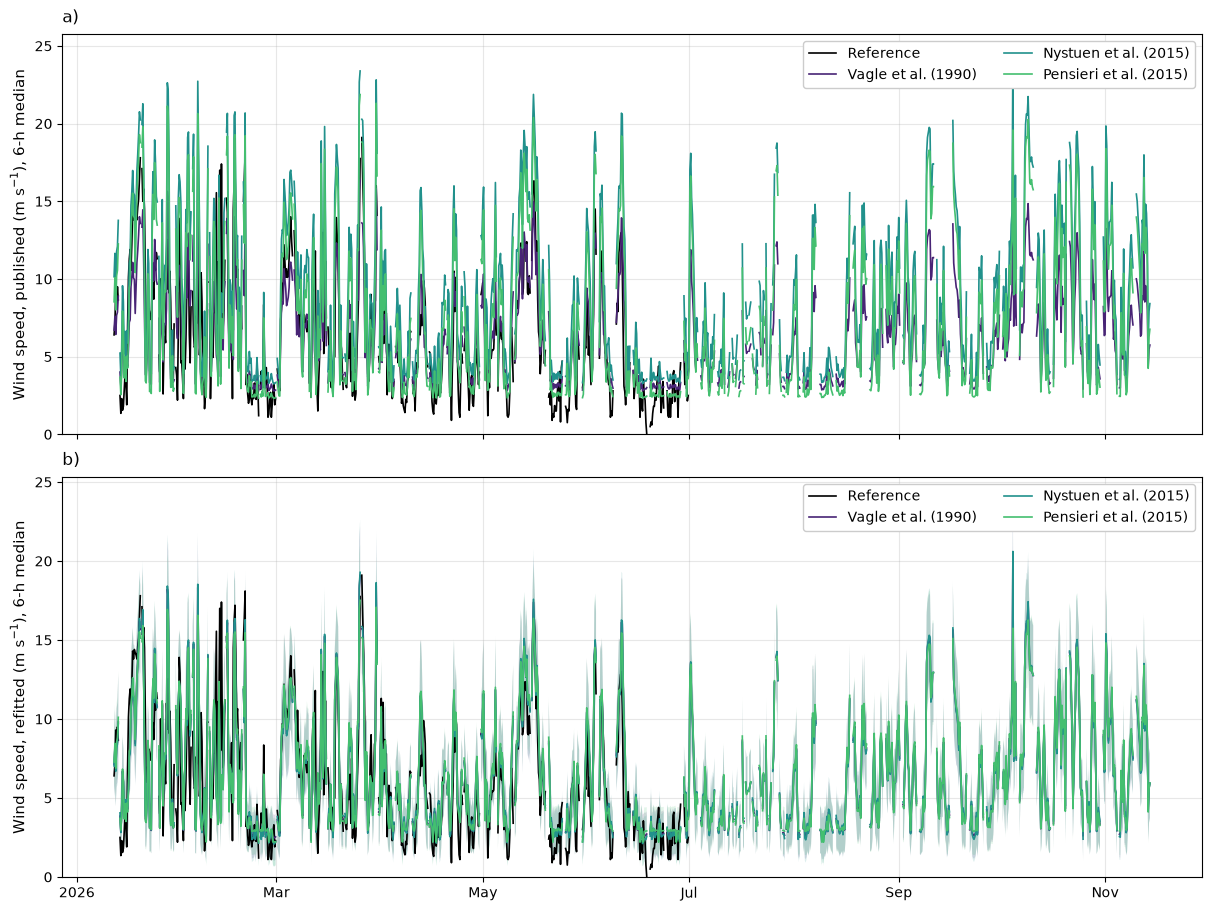

In [24]:
fig, axes = argopal.plot_wind(cal["park"])

### More with references

The same steps can be run one by one on any processed table, here the
raw-mode `park` table from section 3, which has no reference yet.

**Radius.** `fit_max_distance_km` in `process_float`, or `max_distance_km`
in `fit_wind_models`, `wind_skill` and `wind_uncertainty`, sets how close a
measurement must be to its reference to be used; `None` uses all.

In [25]:
park = argopal.collocate_reference(raw["park"], buoys, name="buoys")
for radius in (10, 25, 40, 80):
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        _, fits = argopal.fit_wind_models(park, max_distance_km=radius)
    row = fits.set_index("model").loc["nystuen2015"]
    print(f"{radius:>3} km: n = {row['n']:>6}, RMSE = {row['rmse_fitted']:.2f}, "
          f"R² = {row['r2_fitted']:.2f}")

 10 km: n =      0, RMSE = nan, R² = nan
 25 km: n =    437, RMSE = 1.37, R² = 0.56
 40 km: n =    930, RMSE = 1.99, R² = 0.71
 80 km: n =   2973, RMSE = 2.29, R² = 0.65


No measurement is within 10 km of a buoy, so nothing is refitted there
(the model keeps its row, with n = 0).  The RMSE grows with the radius, as
buoy winds further from the float represent its wind less well; R² also
depends on the range of winds covered, which is narrower within 25 km.

**Which reference each measurement used.**  The closest buoy with a value
within `max_time` (1 h by default), with its distance and time difference:

In [26]:
park[["datetime", "U_buoys", "buoys_reference_name", "buoys_distance_km",
      "buoys_dt_min"]].dropna().iloc[::5000]

,datetime,U_buoys,buoys_reference_name,buoys_distance_km,buoys_dt_min
0,2026-01-12 04:48:59.446877696,6.4,DYFAMED,110.617682,11.000000
5012,2026-02-02 02:12:53.042608128,4.8,DYFAMED,91.537823,-12.900000
10012,2026-02-21 09:48:55.678536704,8.3,PACA,135.752345,-48.933333
15012,2026-03-12 17:19:36.366290944,6.8,DYFAMED,74.795292,-19.616667
20012,2026-04-01 00:19:26.565256192,10.5,PACA,29.308264,-19.450000
25172,2026-04-20 21:59:58.792952832,6.2,PACA,26.492344,0.016667
30184,2026-05-09 20:21:48.502593536,5.8,PACA,57.303508,-21.816667
35184,2026-05-31 02:33:37.635201536,4.6,PACA,57.879600,26.366667
40184,2026-06-21 09:11:28.697395712,2.1,PACA,61.763124,-11.483333


**Averaging window.**  `window` in `fit_wind_models` (or
`reference_window` in `process_float`) sets how much float data is
averaged around each buoy value: `"1h"` (default) is 30 min before to
30 min after.  `"nearest"` averages the measurements whose nearest buoy
value it is, and `average=False` uses every measurement on its own.

In [27]:
for window in ("20min", "1h", "2h"):
    _, fits = argopal.fit_wind_models(park, max_distance_km=40, window=window)
    row = fits.set_index("model").loc["nystuen2015"]
    print(f"{window:>6}: {row['n']} buoy values, "
          f"{row['n_measurements'] / row['n']:.1f} measurements each, "
          f"RMSE = {row['rmse_fitted']:.2f}")
_, fits = argopal.fit_wind_models(park, max_distance_km=40, average=False)
row = fits.set_index("model").loc["nystuen2015"]
print(f"  none: {row['n']} measurements, RMSE = {row['rmse_fitted']:.2f}")

 20min: 921 buoy values, 4.0 measurements each, RMSE = 1.99
    1h: 930 buoy values, 11.8 measurements each, RMSE = 1.99
    2h: 930 buoy values, 23.6 measurements each, RMSE = 1.97
  none: 11178 measurements, RMSE = 1.99


**Collocation time limit and distance.**  `max_time` sets how far in
time the nearest buoy value may be;
`max_distance_km` in `collocate_reference` blanks reference values further
away than that (by default they are kept, so that fitting and figures can
choose).

In [28]:
strict = argopal.collocate_reference(
    raw["park"], buoys, name="buoys", max_time="30min", max_distance_km=40
)
print(f"{strict['U_buoys'].notna().sum()} measurements with a buoy wind "
      f"within 30 min and 40 km, of {len(strict)}")

10982 measurements with a buoy wind within 30 min and 40 km, of 72136


**Skill per reference.**  `by_reference=True` adds one set of rows per
buoy to the skill table:

In [29]:
fitted, _ = argopal.fit_wind_models(park, max_distance_km=40)
skill = argopal.wind_skill(fitted, max_distance_km=40, by_reference=True)
skill[skill["wind"] == "U_nystuen2015_fit"].round(2)

,wind,reference,reference_name,n,bias,rmse,r2,pearson_r2,slope,intercept
3,U_nystuen2015_fit,buoys,all,930,-0.00,1.99,0.71,0.71,0.71,1.52
9,U_nystuen2015_fit,buoys,DYFAMED,334,-0.58,2.31,0.75,0.78,0.68,1.15
15,U_nystuen2015_fit,buoys,PACA,596,0.32,1.78,0.65,0.67,0.76,1.57


**Error of each reference value.**  A `wind_speed_sigma` column in the
table is carried to each measurement (`<name>_sigma`) and used as σ_ref by
`wind_uncertainty`, unless `reference_sigma` is given.  The values below
are only for illustration: these buoys do not give an error per value.

In [30]:
illustrative = buoys.assign(
    wind_speed_sigma=buoys["reference_name"].map(
        {"DYFAMED": 0.5, "LION": 0.5, "PACA": 0.8}
    )
)
p = argopal.collocate_reference(raw["park"], illustrative, name="buoys")
p, _ = argopal.fit_wind_models(p, models=["nystuen2015"])
p, _ = argopal.wind_uncertainty(p, n_bootstrap=20)
print("σ_ref from the table:", round(p.attrs["wind_uncertainty"]["models"]
                                    ["nystuen2015"]["sigma_ref"], 2))

σ_ref from the table: 0.71


**Other table layouts.**

- Column names are recognised from common aliases (`time`, `ff`, `u10`,
  `lat`, `lon`, `station`, `buoy_name`, `sigma`, ...); see
  `argopal.read_reference`.
- A single fixed buoy whose table has no position columns:
  `argopal.collocate_reference(park, "buoy.csv", latitude=43.36, longitude=7.84)`.
- Moving references (ships, drifters): positions are read for every value.
- A dict collocates several sources separately, each under its own name:
  `reference={"dyfamed": "dyfamed.csv", "paca": "paca.csv"}`, with
  `fit_reference="paca"` to choose the one used for refitting.

## 8. Ship noise with AIS (optional)

Ship noise can dominate the 8 kHz band up to ~20 km away.  Given AIS vessel
positions for the float's area and period, measurements with a vessel within
20 km and ±30 min are flagged (`ships_nearby`, `ship_flag`).  With a
reference buoy as well, measurements whose refitted wind also deviates from
the buoy by more than the RMSE are marked `ship_contaminated`
(`ais_action="remove"` blanks only those).

No AIS data cover 7902280's 2026 track here, so this cell is not run.  AIS
can be a table (`datetime`, `mmsi`, `latitude`, `longitude`), decoded CSV
files, or raw NMEA files with tag-block receiver times (needs
`pip install argopal[ais]`):

```python
res = argopal.process_float(
    7902280,
    ais="AIS/messages-*.gz",          # or a DataFrame / CSV files
    reference="reference_winds.csv",
    ais_action="remove",
)
fig, axes = argopal.plot_ais(res["park"])
```

## 9. Export

Any table, or any set of tables, at any stage, as CSV or NetCDF:

In [31]:
argopal.export(cal, "output/wmo7902280", format="csv")

['output/wmo7902280_park.csv',
 'output/wmo7902280_pal_raw.csv',
 'output/wmo7902280_park_samples.csv',
 'output/wmo7902280_profiles.csv',
 'output/wmo7902280_ts_profiles.csv',
 'output/wmo7902280_wind_fits.csv',
 'output/wmo7902280_wind_skill.csv',
 'output/wmo7902280_wind_uncertainty.csv',
 'output/wmo7902280_beta.csv',
 'output/wmo7902280_positions.csv']

In [32]:
files = argopal.export(cal, "output/wmo7902280.nc", format="netcdf")
back = argopal.read_export(files[0])
list(back), back["park"].shape

(['park',
  'pal_raw',
  'park_samples',
  'profiles',
  'ts_profiles',
  'wind_fits',
  'wind_skill',
  'wind_uncertainty',
  'beta',
  'positions'],
 (72136, 72))

In [33]:
argopal.export(pal, "output/pal_step_by_step.csv")   # a single intermediate table

['output/pal_step_by_step.csv']